# Select a condenser convergence angle

Use the microscope recovered by the [beam-image calibration notebook](../microscope_calibration_pipeline.ipynb) to choose a focused illumination angle by gradient descent. This notebook loads the saved fit independently, then generates the control map, descent paths, and target-error figure.

**1. Load the calibrated microscope.** The default dataset is the saved 200 kV calibration used for the figure. Set `experiment_directory` to another completed calibration directory containing `fit.json` and `experiment.json` to use that fit.

In [1]:
%matplotlib inline

import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import json
import sys
from pathlib import Path
import jax
jax.config.update("jax_enable_x64", True)

# Resolve paths from either the notebook folder or the repository root.
repository = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src/temgym_core").is_dir()
)
notebook_directory = repository / "examples/microscope_models/convergence angle"
experiment_directory = repository / "examples/generated/microscope_calibration_tilt_y_notebook"
figure_directory = notebook_directory / "figures"
if str(notebook_directory) not in sys.path:
    sys.path.insert(0, str(notebook_directory))

microscope = json.loads((experiment_directory / "fit.json").read_text())
print("Loaded calibrated microscope:", experiment_directory)


Loaded calibrated microscope: /Users/landers/TemGymCore/examples/generated/microscope_calibration_tilt_y_notebook


**2. Choose a convergence angle with the calibrated condenser.** Once the lens geometry and excitation response are fitted, gradients through the same optics can select a new illumination condition. The figure below tunes **CL3 and the mini condenser** to four requested angles from a common starting setting, while CL1, the source, the 50 µm aperture, and the objective current remain fixed.

We define the transmitted beam's RMS convergence angle as
$$
\alpha = \sqrt{\frac{\operatorname{Var}(\theta_x)+\operatorname{Var}(\theta_y)}{2}},
$$
and require its waist at the specimen. For specimen covariance $\Sigma$, the waist offset in a local drift is
$$
z_w=-\frac{\operatorname{tr}\Sigma_{x\theta}}{\operatorname{tr}\Sigma_{\theta\theta}}.
$$
Projected gradient descent minimizes
$$
L=\tfrac12\left[\left(\frac{\alpha-\alpha_{\rm target}}{10\,\mathrm{mrad}}\right)^2
+\left(\frac{z_w}{10\,\mathrm{\mu m}}\right)^2\right],
$$
using JAX gradients and a backtracking step size. The relative-current bounds are **1.64–1.80 for CL3** and **2.40–2.65 for mini**; these define the illustrated operating range. The dashed curve independently maps settings with a waist at the specimen, and supplies the focused-angle range without initializing the descent runs.

The calculation uses `microscope` from the saved image fit loaded above and the same aperture-diffraction setting as the acquisition. The RMS angle describes the transmitted distribution; a hard cone semi-angle would require a different angular-profile definition.

Focused RMS-angle range in this control box: 6.925–25.604 mrad
Target   8.0 → 8.000019 mrad;  94 steps; waist offset 8.5e-06 µm
Target  12.0 → 11.999996 mrad;  25 steps; waist offset -1.7e-06 µm
Target  18.0 → 18.000000 mrad;  24 steps; waist offset -2e-05 µm
Target  24.0 → 23.999983 mrad;  20 steps; waist offset 2.6e-06 µm
Saved figure and numerical results: /Users/landers/TemGymCore/examples/microscope_models/convergence angle/figures/condenser_convergence_control


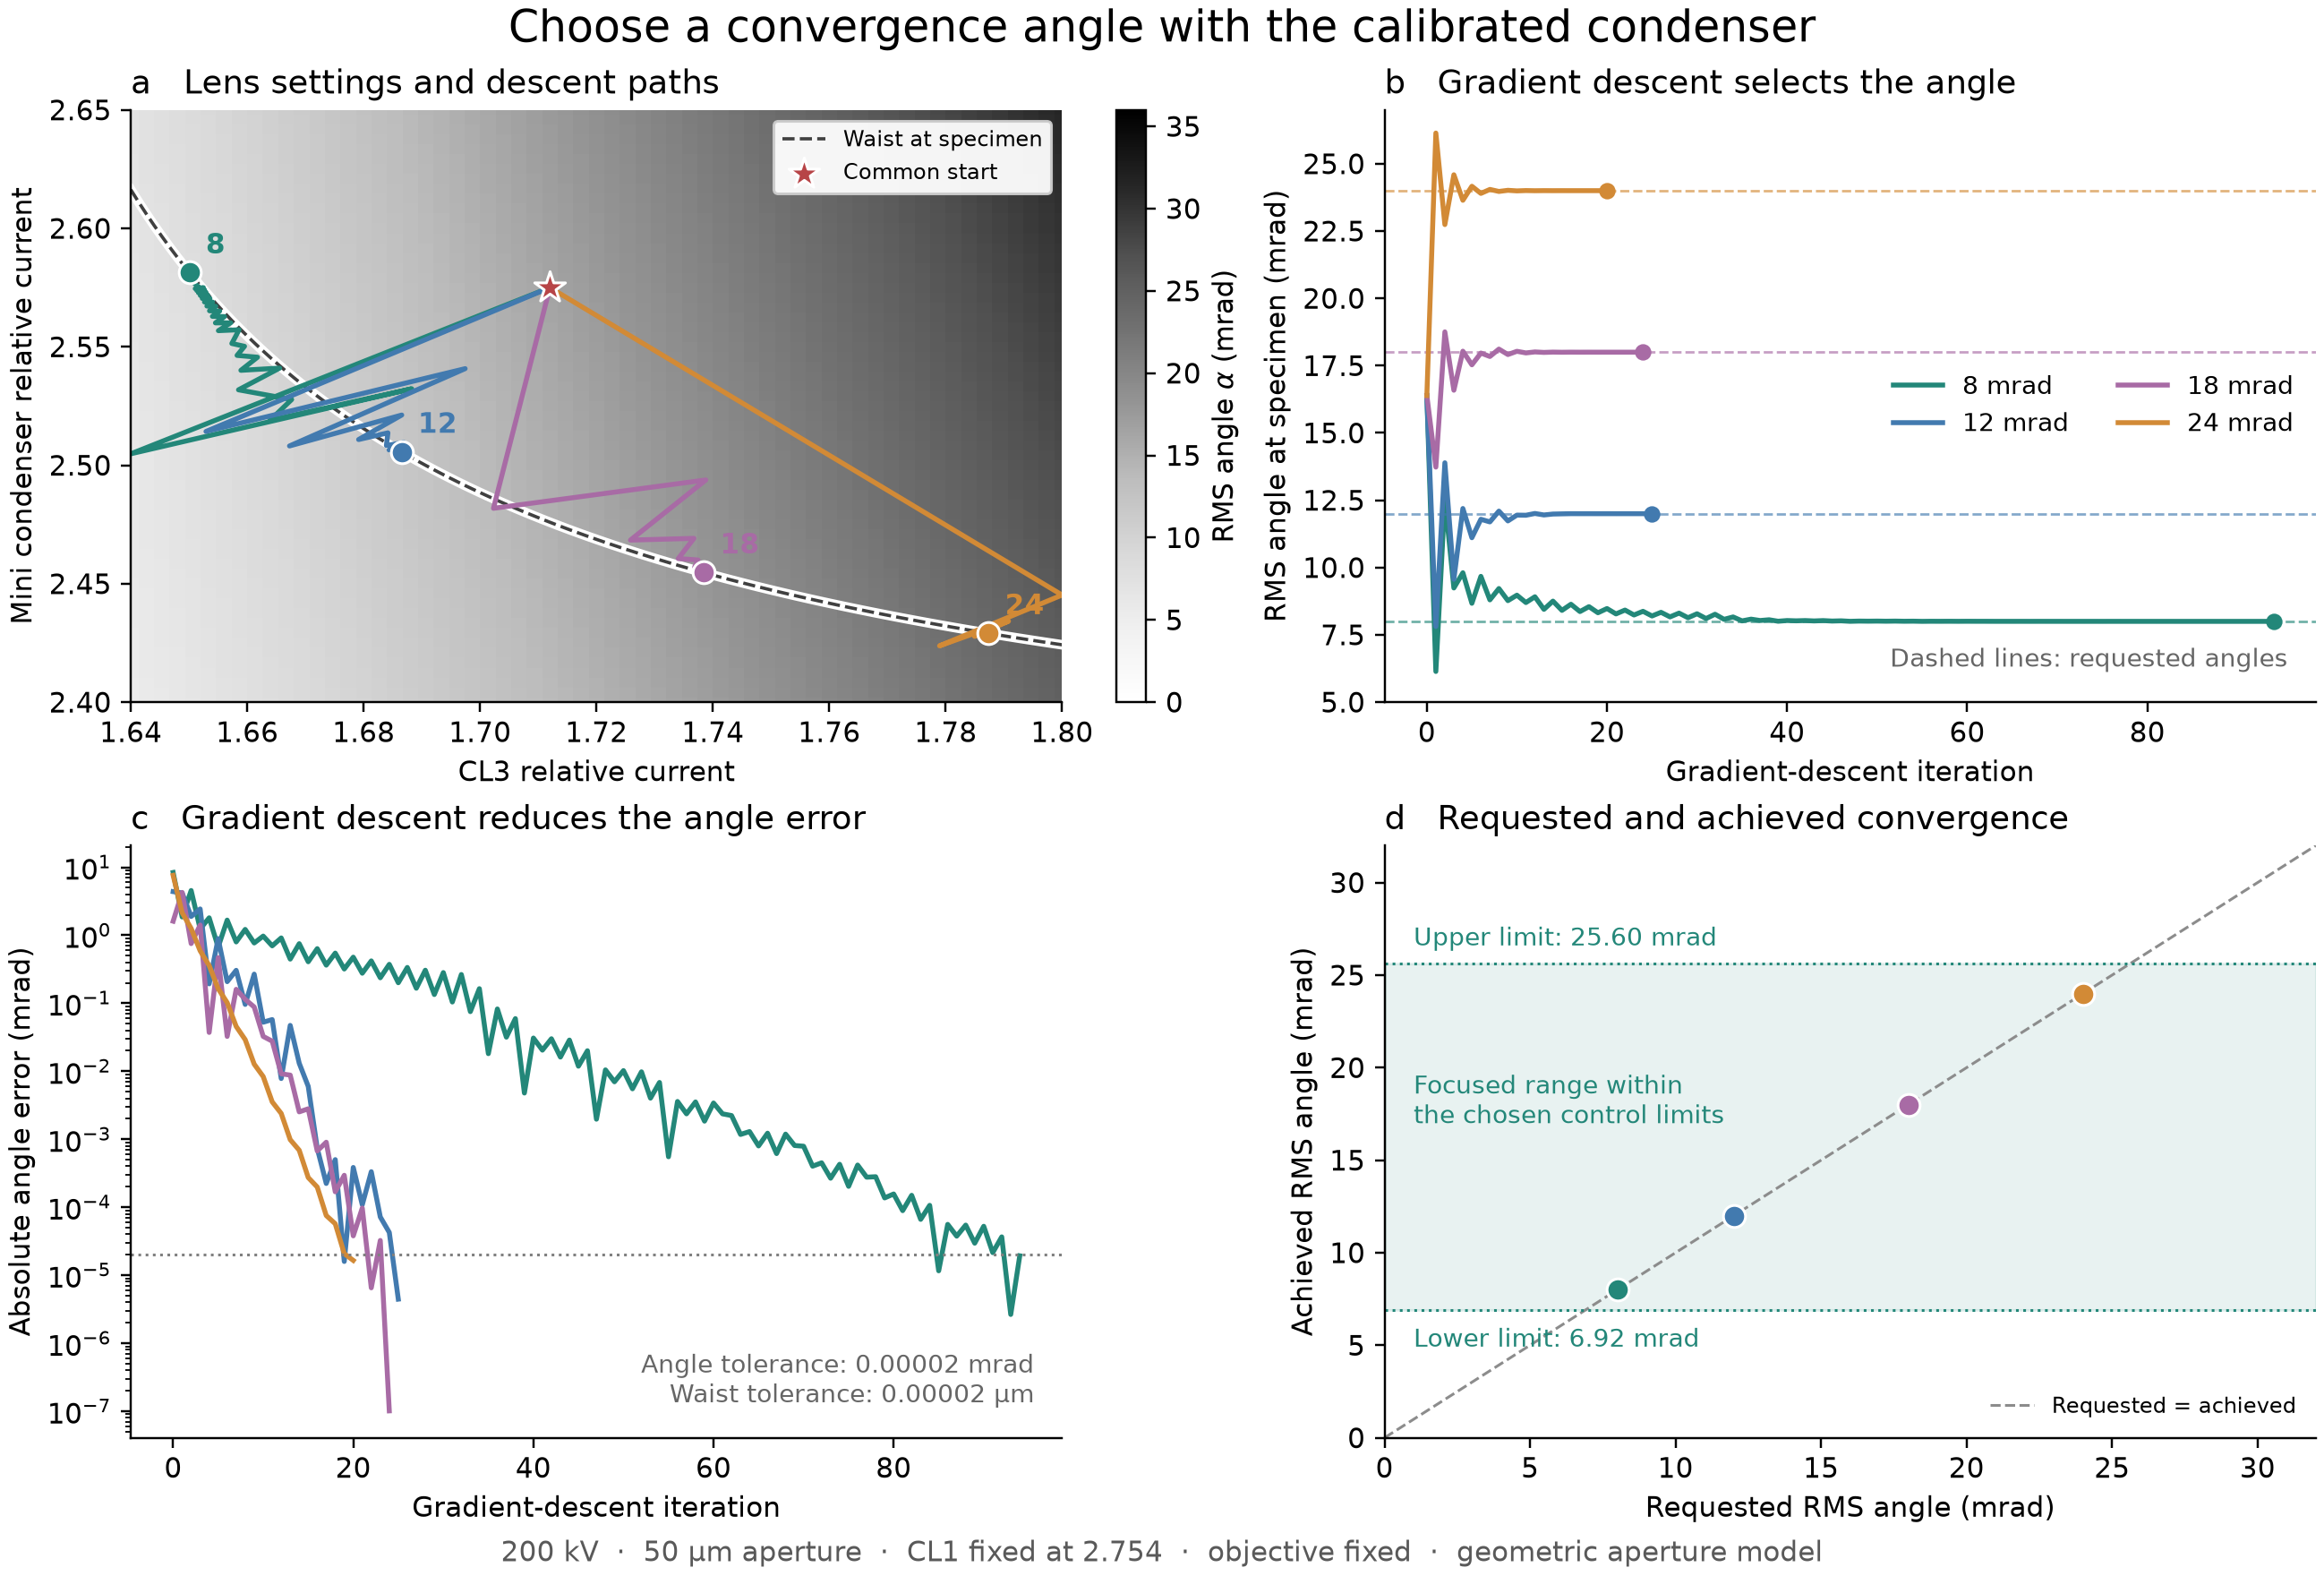

In [2]:
import matplotlib.pyplot as plt
from IPython.display import Image, display
from make_condenser_convergence_figure import build_figure

with plt.ioff():
    convergence_figure, convergence_results = build_figure(
        microscope=microscope,
        experiment_directory=experiment_directory,
        output_directory=figure_directory,
    )
    plt.close(convergence_figure)
# Embed a static figure as well as saving publication exports.
display(Image(filename=str(figure_directory / "condenser_convergence_control.png")))


**Condenser control after calibration.** (a) The fitted angular response across the chosen current bounds, with gradient-descent paths from the common starting point to four focused settings. (b) The angle approaches each requested value, shown by a dashed line. (c) The absolute angle error decreases until both angle and waist tolerances are met. (d) The final angles agree with the requests within the focused range mapped in green.

For the saved 200 kV fit, this control box spans **6.925–25.604 mrad RMS** at a specimen waist; targets of **8, 12, 18, and 24 mrad** converge in **20–94 steps**. CL1 stays at 2.754, preserving the first crossover between CL1 and CL3. These are predictions of the fitted paraxial, geometric-aperture model over the stated bounds; experimental angle accuracy also depends on calibration uncertainty and the validity of that model. The stopping tolerances quantify numerical optimization error.

The cell saves PNG, PDF, SVG, and the currents, iteration histories, and numerical checks as JSON in `figures/condenser_convergence_control.*`. It checks the gradients against finite differences and repeats the endpoint predictions with finer aperture quadrature.

**3. Watch the beam change during gradient descent.** The angle is set by the spread of ray slopes at the specimen, so a wider cone in the specimen zoom means a larger convergence angle. A focused beam also has its narrowest point at the specimen. Matching the angle alone could leave that point above or below the specimen, which is why the loss includes both angle error and waist offset.

At each step, the fitted model predicts how small changes in CL3 and mini change the loss. Gradient descent moves the two currents in the direction that reduces it, shortening the step when necessary and keeping both currents within the specified bounds. Both lenses affect the angle and focus, so their currents change together. Intermediate angles can overshoot even while the combined loss decreases.

The animation replays every accepted step for the **24 mrad** target. Initially, the RMS angle is **16.338 mrad** and the waist is **5.906 µm upstream** of the specimen. By the final step, the beam has the requested angle and its waist coincides with the specimen. CL1 stays fixed, so the first crossover between CL1 and CL3 stays in place while the downstream crossovers move.

The first two panels use TemGym's `trace_ray_envelope` and `plot_ray_bundle` with the fitted native lens components and a representative source bundle clipped at the nominal aperture radius. The specimen zoom shows the **±1 RMS radius calculated from the smooth-aperture moments used by the optimizer**. Its dashed reference is the requested RMS cone, and the horizontal lines mark the specimen and current waist. The small region after the specimen is a local vacuum-drift continuation for locating the waist. All axes remain fixed across steps and targets; the displayed cone angles are exaggerated by the different axial and transverse scales.

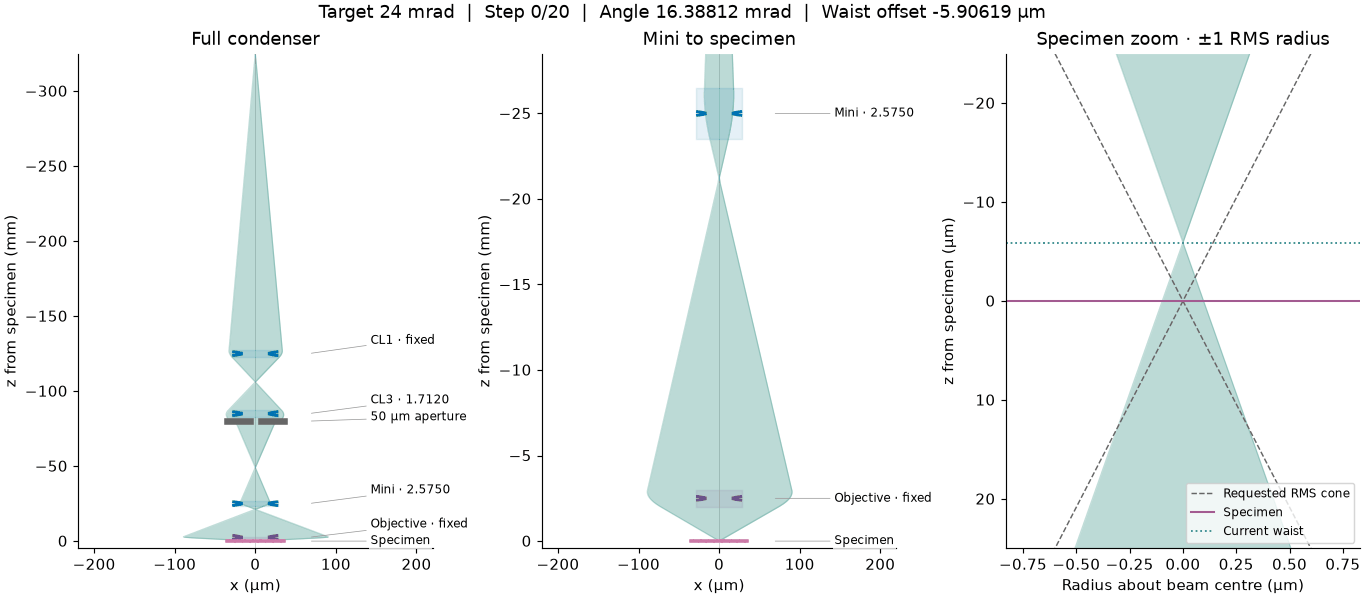

In [3]:
from convergence_ray_viewer import ConvergenceRayViewer

ray_viewer = ConvergenceRayViewer(
    results=convergence_results,
    experiment_directory=experiment_directory,
)
ray_comparison = ray_viewer.save_comparison(figure_directory, target=24.)
ray_animation = ray_viewer.save_animation(figure_directory, target=24.)
display(Image(filename=str(ray_animation)))


**Explore the steps yourself.** Choose 8, 12, 18, or 24 mrad, then press **Play** or move the **Iteration** slider. **Final setting** jumps to the converged beam; **Restart** returns to the shared starting point. The readout gives the actual lens currents, angle error, and signed waist offset at that accepted step. A negative offset places the waist upstream of the specimen.

Run this cell in a live notebook to use the controls. The GIF above also plays without a running kernel. The [initial/final ray comparison](figures/condenser_ray_evolution.pdf) is saved for export.

In [4]:
ray_controls = ray_viewer.widget(initial_target=24.)
display(ray_controls)
